# 1. Data processing

*Series:* **[1. Data processing](01_data_processing.ipynb)** · [2. Exploratory analysis](02_exploratory_analysis.ipynb) · [3. Classification](03_classification.ipynb) · [4. Clustering](04_clustering.ipynb) · [5. Explainability](05_explainability.ipynb)

---

This notebook loads the raw file, shows that its most important defect is
invisible on inspection, fixes that defect, and writes the result to
`data/processed/`.

It does not impute. Unmasking a disguised zero is a pure relabelling: a 0
becomes a NaN and nothing is estimated from other patients, so it is safe to do
once, before any train/test split. Imputation learns values from the data, so it
has to live inside a pipeline that is refit on every fold. A `cleaned.csv` with
the gaps already filled is the artefact that makes leakage invisible three
notebooks later.

In [1]:
import warnings

import numpy as np
import pandas as pd

from pima import eda, plots
from pima.data import FEATURES, IMPOSSIBLE_ZERO_COLUMNS, TARGET, load_raw, missingness_report, save_processed, unmask_missing

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plots.use_style()

## Loading the raw file

`load_raw` checks the expected schema on the way in (the eight feature columns,
a binary `Outcome`) and raises if it fails, so a file with a missing column
cannot load half-valid and produce an error somewhere far from its cause.

In [2]:
raw = load_raw()
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
print(f"duplicate rows: {raw.duplicated().sum()}")
print(f"explicitly missing values: {raw.isna().sum().sum()}")
raw.head()

768 rows x 9 columns
duplicate rows: 0
explicitly missing values: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


## Zeros that are not measurements

There are no explicitly missing values, which is a problem rather than a
reassurance. Look at the `min` column above: a minimum of 0 for `Glucose`,
`BloodPressure`, `SkinThickness`, `Insulin` and `BMI`.

A living patient cannot have a blood glucose of zero, a blood pressure of zero,
a skin fold thickness of zero, a serum insulin of zero, or a BMI of zero. These
are missing measurements that whoever assembled the file recorded as `0`. An
analysis that takes them at face value computes averages over patients who do
not exist.

In [4]:
zeros = pd.DataFrame({
    "feature": FEATURES,
    "n_zeros": [(raw[c] == 0).sum() for c in FEATURES],
}).assign(
    pct=lambda d: (100 * d["n_zeros"] / len(raw)).round(1),
    biologically_possible=lambda d: ~d["feature"].isin(IMPOSSIBLE_ZERO_COLUMNS),
)
zeros.sort_values("n_zeros", ascending=False)

,feature,n_zeros,pct,biologically_possible
4,Insulin,374,48.7,False
3,SkinThickness,227,29.6,False
0,Pregnancies,111,14.5,True
2,BloodPressure,35,4.6,False
5,BMI,11,1.4,False
1,Glucose,5,0.7,False
6,DiabetesPedigreeFunction,0,0.0,True
7,Age,0,0.0,True


### Pregnancies is a genuine zero

`Pregnancies` has 111 zeros and every one is a real measurement: a patient who
has never been pregnant. Applying "replace zeros with NaN" across all columns,
which is the obvious one-liner, would silently delete 14.5% of the cohort (111
patients) from the dataset's most complete feature.

The distinction is encoded in `IMPOSSIBLE_ZERO_COLUMNS` and pinned by a unit
test (`test_data.py::test_unmask_only_touches_impossible_columns`), since it is
the kind of thing a later refactor tends to flatten.

In [5]:
df = unmask_missing(raw)
print(f"zeros in Pregnancies, before: {(raw['Pregnancies'] == 0).sum()}  "
      f"after: {(df['Pregnancies'] == 0).sum()}")
print(f"missing values now explicit: {df.isna().sum().sum()}")

zeros in Pregnancies, before: 111  after: 111
missing values now explicit: 652


## Missingness after unmasking

In [6]:
report = missingness_report(df)
report

,feature,n_missing,pct_missing,diabetes_rate_when_missing,overall_diabetes_rate
0,Insulin,374,48.7,0.369,0.349
1,SkinThickness,227,29.6,0.388,0.349
2,BloodPressure,35,4.6,0.457,0.349
3,BMI,11,1.4,0.182,0.349
4,Glucose,5,0.7,0.400,0.349
5,Pregnancies,0,0.0,NaN,0.349
6,DiabetesPedigreeFunction,0,0.0,NaN,0.349
7,Age,0,0.0,NaN,0.349


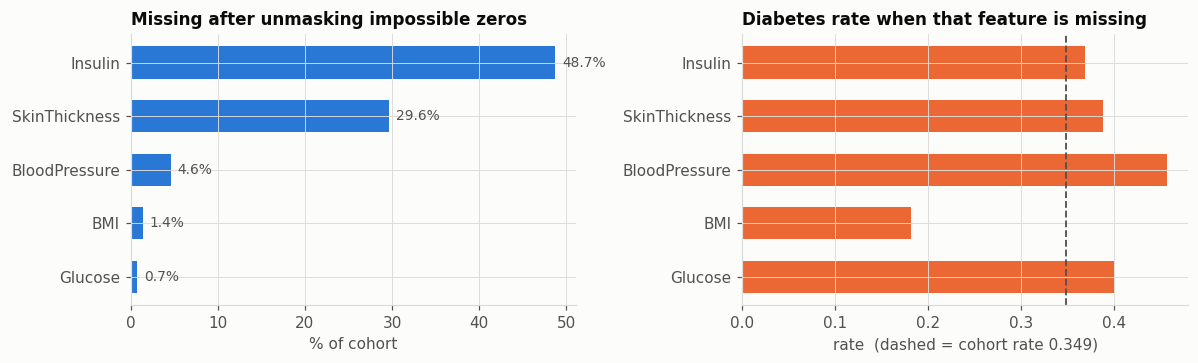

In [7]:
plots.missingness(report);

Nearly half of `Insulin` and almost a third of `SkinThickness` were never
recorded. This is the dominant fact about the dataset and it constrains
everything in the notebooks that follow.

The right panel asks whether the missingness is *informative*: whether "no
measurement taken" is itself a signal. Rows missing `Insulin` are 36.9%
diabetic against a cohort rate of 34.9%, a two-point difference across 374
patients, which is well inside noise. `BMI` looks more dramatic at 18.2%, but
that is 2 diabetics out of 11 rows.

Missingness therefore carries little information about the outcome, at least
by this crude measure. A proper test is to fit a model with and without
missing-value indicators and compare, which is a job for the modelling stage.

## Which features go missing together

Whether the gaps are independent matters more than their individual counts. Two
features each 30% missing at random leave much more recoverable information
than two features that are always missing together.

In [8]:
overlap = eda.comissingness(df)
overlap

,Glucose,BloodPressure,SkinThickness,Insulin,BMI
Glucose,5,0,0,4,0
BloodPressure,0,35,33,35,7
SkinThickness,0,33,227,227,9
Insulin,4,35,227,374,10
BMI,0,7,9,10,11


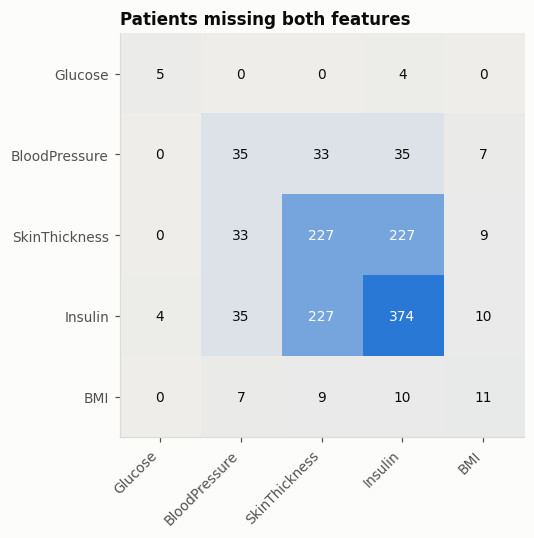

In [9]:
plots.comissingness_heatmap(overlap);

The gaps are nested inside one another. Every one of the 227 patients missing
`SkinThickness` is also missing `Insulin`, and so is every one of the 35 missing
`BloodPressure`. `Insulin`'s 374 missing rows contain essentially all the other
gaps.

What that describes is a single event: a patient who did not receive a
particular workup. Two predictions follow from it, both testable once there is a
model to test them on:

1. **Missing-value indicators should be nearly collinear.** They encode
   roughly the same binary fact, so adding all five ought to buy almost nothing
   over adding one.
2. **Sophisticated imputation should have little to work with.** Iterative
   imputation estimates a missing feature from the others, but for these
   patients the correlated features are missing too, so it has nothing to
   condition on. If that reasoning holds it will score no better than a plain
   median.

## Sanity check after unmasking

Unmasking should leave the summary statistics more plausible than before. A
value that now looks impossible would mean the rule was applied too widely.

In [10]:
eda.distribution_summary(df)

,feature,n,mean,median,sd,min,max,skew,excess_kurtosis
0,Pregnancies,768,3.85,3.00,3.37,0.00,17.00,0.90,0.16
1,Glucose,763,121.69,117.00,30.54,44.00,199.00,0.53,-0.28
2,BloodPressure,733,72.41,72.00,12.38,24.00,122.00,0.13,0.91
3,SkinThickness,541,29.15,29.00,10.48,7.00,99.00,0.69,2.94
4,Insulin,394,155.55,125.00,118.78,14.00,846.00,2.17,6.37
5,BMI,757,32.46,32.30,6.92,18.20,67.10,0.59,0.86
6,DiabetesPedigreeFunction,768,0.47,0.37,0.33,0.08,2.42,1.92,5.59
7,Age,768,33.24,29.00,11.76,21.00,81.00,1.13,0.64


Every range is now clinically plausible: glucose 44 to 199, BMI 18.2 to 67.1, blood
pressure 24 to 122. The minimum insulin of 14 and maximum of 846 are extreme but
real; the maximum BMI of 67.1 is a genuine severe-obesity reading.

Two columns are worth carrying forward. `Insulin` has a skew of 2.17, excess
kurtosis of 6.37, and a standard deviation (118.8) close to its own mean
(155.6). It is by far the widest-ranging feature, which is what makes the raw scale
dangerous for any distance-based method: on unstandardised data, Euclidean
distance between two patients would be mostly insulin distance.

## Write the processed dataset

In [11]:
path = save_processed(df)
print(f"wrote {path.relative_to(path.parents[2])}")
print(f"{len(df)} rows, {df.isna().sum().sum()} explicit missing values preserved as NaN")

wrote data\processed\diabetes_unmasked.csv
768 rows, 652 explicit missing values preserved as NaN


---
## Summary

- The dataset's 768 rows contain no duplicates and, as distributed, no explicit
  missing values, because 652 missing measurements were written as zeros.
- Unmasking those affects five columns. `Pregnancies` zeros are real and are
  left alone.
- `Insulin` is 48.7% missing and `SkinThickness` 29.6%.
- The gaps are nested inside one another, so they represent a single "workup
  not performed" event instead of five independent ones.
- Missingness carries little information about the outcome.

Next: [2. Exploratory analysis](02_exploratory_analysis.ipynb).